In [10]:
# Actividad 2. Python para análisis de datos

## Conjunto de datos Se utiliza Palmer Penguins, un conjunto de datos que contiene información de tres especies de pingüinos observados en el archipiélago Palmer, en la Antártida.
## Actividades 1. Crear gráficos para visualizar y comparar variables. 2. Definir funciones sencillas para reutilizar código.3. Interpretar los resultados obtenidos.
    
import pandas as pd
import matplotlib.pyplot as plt

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [11]:
# Cargar el conjunto de datos
datos = pd.read_csv("pinguinos.csv")

# Mostrar las primeras filas
datos.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [12]:
# Consultar dimensiones
print("Dimensiones:", datos.shape)

# Consultar valores faltantes
print("Valores faltantes por variable:")
print(datos.isnull().sum())

# Consultar las especies
print("Especies:", datos["species"].unique())

Dimensiones: (344, 7)
Valores faltantes por variable:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Especies: <ArrowStringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str


In [3]:
def calcular_promedio(datos, variable):
    return datos[variable].mean()

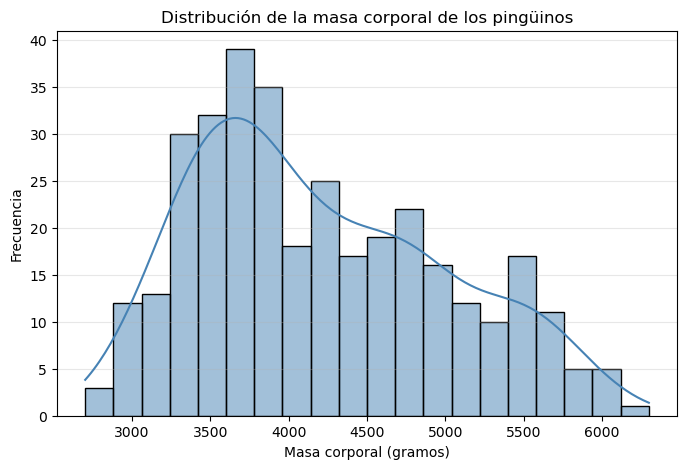

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

# Histograma de masa corporal
sns.histplot(
    datos["body_mass_g"].dropna(),
    bins=20,
    kde=True,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución de la masa corporal de los pingüinos")
plt.xlabel("Masa corporal (gramos)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)

plt.show()

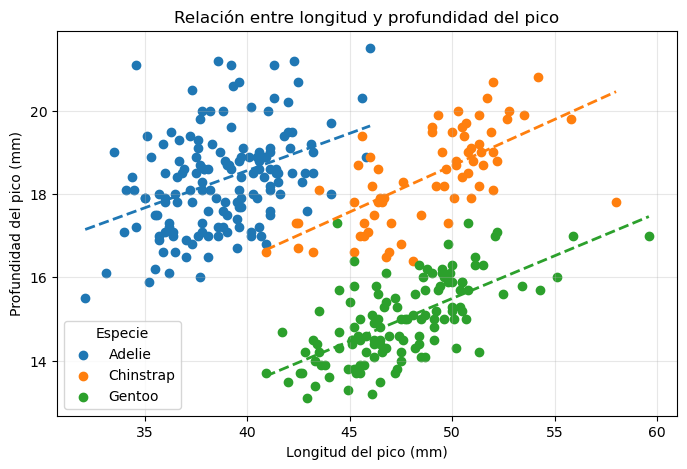

In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for especie in datos["species"].dropna().unique():

    # Seleccionar los datos de cada especie
    grupo = datos[datos["species"] == especie].dropna(
        subset=["bill_length_mm", "bill_depth_mm"]
    )

    # Crear gráfico de dispersión
    plt.scatter(
        grupo["bill_length_mm"],
        grupo["bill_depth_mm"],
        label=especie
    )

    # Calcular la línea de tendencia
    pendiente, intercepto = np.polyfit(
        grupo["bill_length_mm"],
        grupo["bill_depth_mm"],
        1
    )

    # Generar los valores de la línea
    x = np.linspace(
        grupo["bill_length_mm"].min(),
        grupo["bill_length_mm"].max(),
        100
    )

    y = pendiente * x + intercepto

    # Dibujar la línea de tendencia
    plt.plot(x, y, linestyle="--", linewidth=2)

plt.title("Relación entre longitud y profundidad del pico")
plt.xlabel("Longitud del pico (mm)")
plt.ylabel("Profundidad del pico (mm)")
plt.legend(title="Especie")
plt.grid(alpha=0.3)
plt.show()

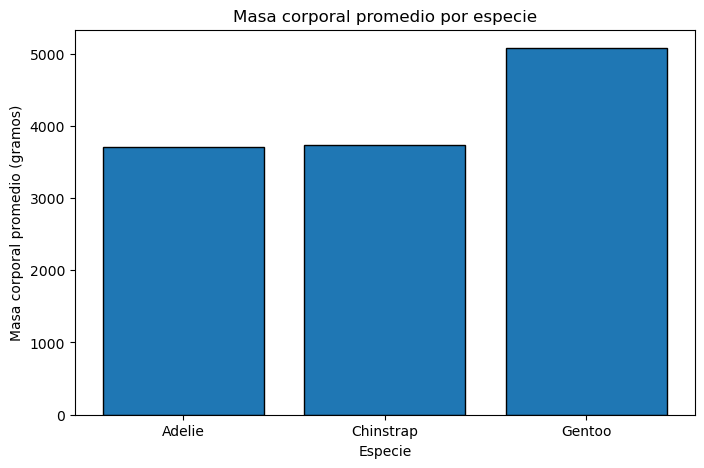

In [18]:
promedios = datos.groupby("species")["body_mass_g"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    promedios.index,
    promedios.values,
    edgecolor="black"
)

plt.title("Masa corporal promedio por especie")
plt.xlabel("Especie")
plt.ylabel("Masa corporal promedio (gramos)")

plt.show()

In [19]:
def calcular_promedio(datos, variable):
    """
    Calcula el promedio de una variable numérica.
    """
    promedio = datos[variable].mean()
    return promedio

In [20]:
promedio_masa = calcular_promedio(datos, "body_mass_g")

print("Masa corporal promedio:", round(promedio_masa, 2), "gramos")

Masa corporal promedio: 4201.75 gramos


In [21]:
def crear_histograma(datos, variable, titulo):
    """
    Crea un histograma de una variable del conjunto de datos.
    """
    plt.figure(figsize=(8, 5))

    plt.hist(
        datos[variable].dropna(),
        bins=20,
        edgecolor="black"
    )

    plt.title(titulo)
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")

    plt.show()

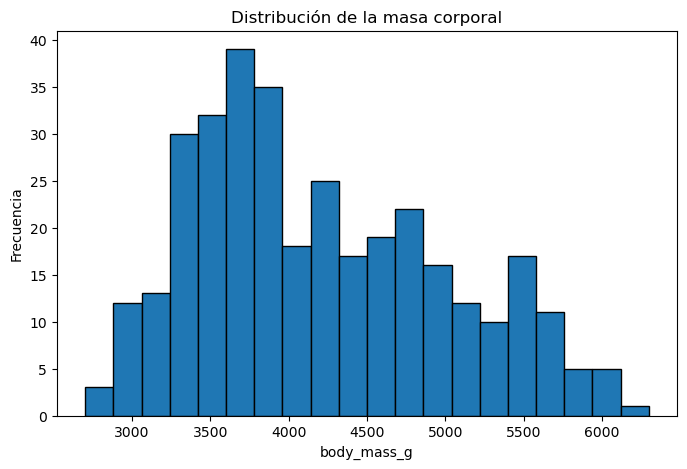

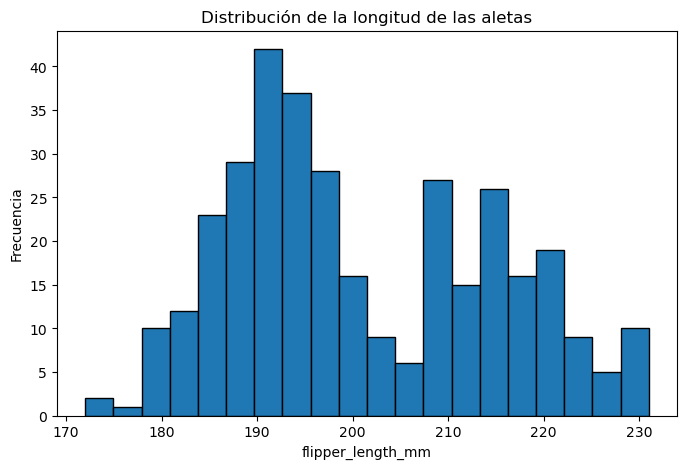

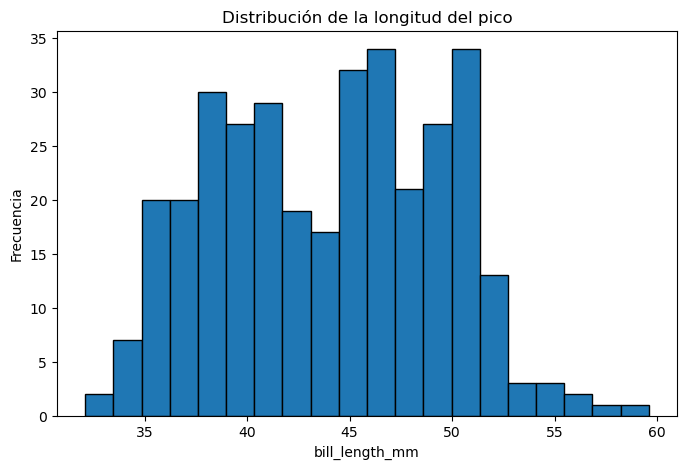

In [22]:
crear_histograma(
    datos,
    "body_mass_g",
    "Distribución de la masa corporal"
)

crear_histograma(
    datos,
    "flipper_length_mm",
    "Distribución de la longitud de las aletas"
)

crear_histograma(
    datos,
    "bill_length_mm",
    "Distribución de la longitud del pico"
)

In [23]:
# Interpretación de resultados

##La visualización permitió explorar las características morfológicas de tres especies de pingüinos: Adelie, Chinstrap y Gentoo.

##El histograma permitió observar la distribución de la masa corporal de los individuos.

##El gráfico de dispersión permitió identificar diferencias en la relación entre la longitud y profundidad del pico según la especie.

##El gráfico de barras facilitó la comparación de la masa corporal promedio entre las tres especies.

## Adicionalmente, las funciones reutilizables permitieron calcular promedios y generar histogramas, reduciendo la repetición de código y facilitando el análisis de datos.